In [3]:
# from graphviz import Digraph

# dot = Digraph()

# dot.node("A", "Entropy = 1.0\nApakah Umur <= 20?")
# dot.node("B", "Kelas = Tidak")
# dot.node("C", "Entropy = 0.5\nApakah Nilai <= 75?")
# dot.node("D", "Kelas = Ya")
# dot.node("E", "Kelas = Tidak")

# dot.edge("A", "B", label="Ya")
# dot.edge("A", "C", label="Tidak")
# dot.edge("C", "D", label="Ya")
# dot.edge("C", "E", label="Tidak")

# dot.render("decision_tree", format="png", view=True)

In [4]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    'Cuaca': ['Cerah', 'Cerah', 'Hujan',
              'Hujan', 'Mendung', 'Mendung'],
    'Keputusan': ['Tidak', 'Tidak', 'Ya',
                  'Ya', 'Ya', 'Ya']
})

print(df)

     Cuaca Keputusan
0    Cerah     Tidak
1    Cerah     Tidak
2    Hujan        Ya
3    Hujan        Ya
4  Mendung        Ya
5  Mendung        Ya


In [5]:
def entropy(data):
    probabilitas = data.value_counts(normalize=True)

    return -sum(
        probabilitas * np.log2(probabilitas)
    )

hasil_entropy = entropy(df['Keputusan'])

print("Entropy:", hasil_entropy)

Entropy: 0.9182958340544896


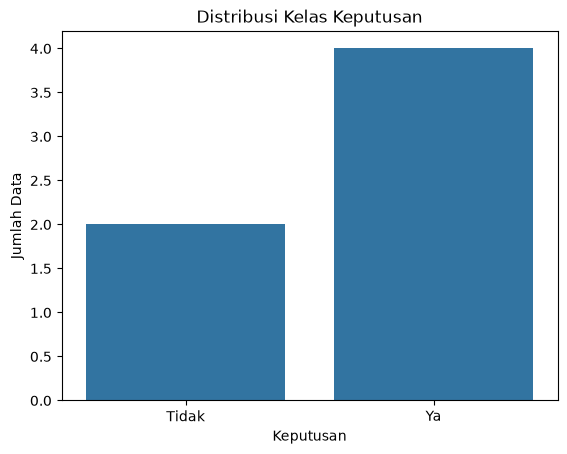

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    data=df,
    x='Keputusan'
)

plt.title('Distribusi Kelas Keputusan')
plt.xlabel('Keputusan')
plt.ylabel('Jumlah Data')
plt.show()

In [7]:
def information_gain(data, fitur, target):
    entropy_awal = entropy(data[target])

    entropy_split = 0

    for nilai in data[fitur].unique():
        subset = data[data[fitur] == nilai]

        entropy_split += (
            len(subset) / len(data)
        ) * entropy(subset[target])

    return entropy_awal - entropy_split


ig = information_gain(
    df,
    'Cuaca',
    'Keputusan'
)

print("Information Gain:", ig)

Information Gain: 0.9182958340544896
